# Error Rate Analysis: Control vs Test
**Vanguard A/B Test – Digital Footprints (`df_final_web_data`)** · Owner: Raquel

### What is this notebook about?
In the new design (Test) and the old design (Control), clients go through these steps:

`start → step_1 → step_2 → step_3 → confirm`

Sometimes a client goes **backwards** (for example from `step_3` back to `step_2`). We treat that as an **error**, because it may mean the client was confused.

### Our goal
Test whether the difference between the error rate of the **Test group** and the **Control group** is **statistically significant**.

### Notebook structure
1. Import libraries
2. Load the data
3. Merge with the experiment roster (to know who is Test / Control)
4. Create the error flag (backward steps)
5. Error rate per group (KPI)
6. Hypothesis test: is the difference real or just chance?
7. Robustness checks: visit level and client level
8. Deeper Control vs Test analysis (context)
9. Final interpretation: results summary
10. Conclusions
11. Group hand-off checklist

## 1. Import libraries
- `pandas` and `numpy` to work with tables and numbers
- `matplotlib` and `seaborn` to make charts
- `statsmodels` for the statistical test

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

# Same colours as the other team notebooks, so all charts in the presentation match
colors = {"Control": "#eb6834", "Test": "#2a78d6"}

## 2. Load the data
Both files are in the project folder `data/clean/`:
- `df_web_clean.csv` (or `df_web_clean.zip`) → Digital Footprints, already cleaned (duplicates removed, dates converted)
- `experiment_clients_clean.csv` → the roster that says who was in **Test** or **Control**

The paths are built from the project folder, so the notebook runs on every team member's computer. The notebook must be saved in `vanguard-ab-test/notebooks/`.

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"

# the web file can be the .csv or the .zip (pandas reads the zip directly)
web_csv = CLEAN_DIR / "df_web_clean.csv"
WEB_FILE = web_csv if web_csv.exists() else CLEAN_DIR / "df_web_clean.zip"
EXPERIMENT_FILE = CLEAN_DIR / "experiment_clients_clean.csv"

for f in (WEB_FILE, EXPERIMENT_FILE):
    if not f.exists():
        raise FileNotFoundError(f"Could not find {f}. Put the file in {CLEAN_DIR}.")

df_web = pd.read_csv(WEB_FILE, parse_dates=["date_time"])
df_exp = pd.read_csv(EXPERIMENT_FILE)
df_exp.columns = df_exp.columns.str.lower().str.strip()

print("Web data shape:", df_web.shape)
print("Experiment roster shape:", df_exp.shape)
df_exp.head()

Web data shape: (744641, 5)
Experiment roster shape: (50500, 2)


,client_id,variation
0,555,Test
1,647,Test
2,934,Test
3,1028,Control
4,1104,Control


## 3. Merge web data with the experiment roster
The web data doesn't say if a client was Test or Control, so we join both tables using `client_id`.

We use `how="inner"` → we **only keep clients that are in both tables** (clients outside the experiment are dropped).

In [3]:
df_web.columns = df_web.columns.str.lower().str.strip()

required_web = {"client_id", "visit_id", "process_step", "date_time"}
required_exp = {"client_id", "variation"}
missing_web = required_web - set(df_web.columns)
missing_exp = required_exp - set(df_exp.columns)
if missing_web:
    raise KeyError(f"Missing required columns in web data: {sorted(missing_web)}")
if missing_exp:
    raise KeyError(f"Missing required columns in experiment roster: {sorted(missing_exp)}")

# A client should have one experiment assignment. Check this before merging.
duplicate_assignments = df_exp["client_id"].duplicated().sum()
print("Duplicate client IDs in experiment roster:", duplicate_assignments)
if duplicate_assignments:
    raise ValueError("The experiment roster contains repeated client_id values.")

df = df_web.merge(df_exp[["client_id", "variation"]], on="client_id", how="inner", validate="many_to_one")
df["variation"] = df["variation"].astype("string").str.strip()
df = df[df["variation"].isin(["Test", "Control"])].copy()

print("Rows after merge:", df.shape[0])
df.groupby("variation")["client_id"].nunique().rename("unique_clients").to_frame()

Duplicate client IDs in experiment roster: 0
Rows after merge: 317235


,unique_clients
variation,
Control,23532
Test,26968


## 4. Create the "error" flag (backward steps)

### 4.1 Give each step a number
| process_step | number |
|---|---|
| start | 0 |
| step_1 | 1 |
| step_2 | 2 |
| step_3 | 3 |
| confirm | 4 |

If the next step has a **smaller** number than the previous one → the client went back.

In [4]:
step_order = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}

df["process_step"] = df["process_step"].astype("string").str.strip()
df["step_num"] = df["process_step"].map(step_order)

unknown_steps = sorted(df.loc[df["step_num"].isna(), "process_step"].dropna().unique().tolist())
print("Steps without a number:", int(df["step_num"].isna().sum()))
if unknown_steps:
    raise ValueError(f"Unexpected step names: {unknown_steps}")

Steps without a number: 0


### 4.2 Make each visit unique and sort in time order ⚠️ (very important)
Two things to fix before comparing steps:

1. **The same `visit_id` is used by different clients** (a few hundred cases). If we group only by `visit_id`, actions of different clients get mixed. So a visit = **`client_id` + `visit_id`** (`visit_key`).
2. **Rows come from the most recent to the oldest** in the original file. We sort each visit by `date_time` (oldest first). When two actions have the **same second**, we put the earlier step first (`step_num`). Otherwise a logging tie would be counted as a fake "error".

These are the same rules used in the other team notebooks (time spent, completion), so all KPIs count visits the same way.

In [5]:
df["visit_key"] = df["client_id"].astype(str) + "_" + df["visit_id"].astype(str)

shared_ids = (df.groupby("visit_id")["client_id"].nunique() > 1).sum()
same_second = df.duplicated(["visit_key", "date_time"]).sum()
print("visit_id values used by more than one client:", shared_ids)
print("Actions in the same second as another action of the same visit:", same_second)

df = df.sort_values(["visit_key", "date_time", "step_num"], kind="stable").reset_index(drop=True)
print("Unique visits by group:")
df.groupby("variation")["visit_key"].nunique().rename("unique_visits").to_frame()

visit_id values used by more than one client: 242
Actions in the same second as another action of the same visit: 528
Unique visits by group:


,unique_visits
variation,
Control,32243
Test,37204


### 4.3 Compare each step with the previous one (inside the same visit)
- `groupby("visit_key")` → we compare only steps **within the same visit**
- `shift()` → brings the previous row's step down to the current row
- If `step_num < previous_step_num` → `backward = True` (an error)

The first step of each visit has no previous step, so it is never an error.

In [6]:
df["previous_step_num"] = df.groupby("visit_key")["step_num"].shift()
df["previous_step"] = df.groupby("visit_key")["process_step"].shift()
df["backward"] = df["step_num"] < df["previous_step_num"]

print("Total backward steps found:", int(df["backward"].sum()))
df[["visit_key", "process_step", "previous_step", "backward"]].head(10)

Total backward steps found: 25661


,visit_key,process_step,previous_step,backward
0,1000062_68804396_74737424429_397490,start,<NA>,False
1,1000062_68804396_74737424429_397490,step_1,start,False
2,1000062_68804396_74737424429_397490,step_2,step_1,False
3,1000062_68804396_74737424429_397490,step_3,step_2,False
4,1000062_68804396_74737424429_397490,confirm,step_3,False
5,1000353_25815056_49382962398_993535,start,<NA>,False
6,1000353_25815056_49382962398_993535,start,start,False
7,1000353_25815056_49382962398_993535,start,start,False
8,1000353_25815056_49382962398_993535,step_1,start,False
9,1000353_25815056_49382962398_993535,step_2,step_1,False


## 5. Error rate per group (KPI)
**Formula (project brief):** error rate = number of backward steps ÷ total number of steps taken

In [7]:
error_table = df.groupby("variation")["backward"].agg(errors="sum", total_steps="count")
error_table["error_rate_%"] = (error_table["errors"] / error_table["total_steps"] * 100).round(2)
error_table

,errors,total_steps,error_rate_%
variation,,,
Control,9484,140536,6.75
Test,16177,176699,9.16


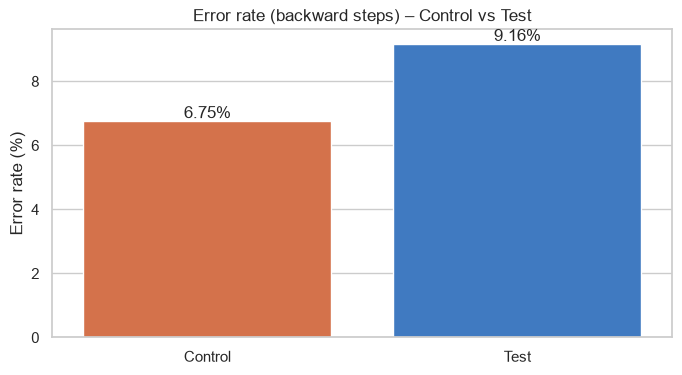

In [8]:
rates = error_table["error_rate_%"].reindex(["Control", "Test"])

ax = sns.barplot(x=rates.index, y=rates.values, hue=rates.index, palette=colors, legend=False)
ax.set_title("Error rate (backward steps) – Control vs Test")
ax.set_xlabel("")
ax.set_ylabel("Error rate (%)")
for i, v in enumerate(rates.values):
    ax.text(i, v + 0.1, f"{v:.2f}%", ha="center")
plt.show()

## 6. Hypothesis test: is the difference real?

The Test group has a higher error rate. Is that a **real** difference, or could it be **random chance**?

### Hypotheses
- **H₀ (null):** the error rate of Test = the error rate of Control (no difference)
- **H₁ (alternative):** the error rate of Test ≠ the error rate of Control (there is a difference)

### Test used: two-proportion z-test
We compare **two proportions** (error rates of two groups), so this is the right test.

### Significance level
**α = 0.05**: p-value < 0.05 → reject H₀ (the difference is statistically significant)

### Requirement of the test
At least ~10 errors and ~10 non-errors in each group.

In [9]:
alpha = 0.05

errors_test = int(error_table.loc["Test", "errors"])
errors_control = int(error_table.loc["Control", "errors"])
n_test = int(error_table.loc["Test", "total_steps"])
n_control = int(error_table.loc["Control", "total_steps"])

print("Requirement check (all should be at least 10):")
print("  Test    -> errors:", errors_test, "| non-errors:", n_test - errors_test)
print("  Control -> errors:", errors_control, "| non-errors:", n_control - errors_control)

Requirement check (all should be at least 10):
  Test    -> errors: 16177 | non-errors: 160522
  Control -> errors: 9484 | non-errors: 131052


In [10]:
z_stat, p_value = proportions_ztest(count=[errors_test, errors_control], nobs=[n_test, n_control],
                                    alternative="two-sided")

rate_test = errors_test / n_test
rate_control = errors_control / n_control
difference_pp = (rate_test - rate_control) * 100

print(f"Error rate Test:    {rate_test*100:.2f}%")
print(f"Error rate Control: {rate_control*100:.2f}%")
print(f"Difference:         {difference_pp:.2f} percentage points")
print(f"z-statistic:        {z_stat:.3f}")
print(f"p-value:            {p_value:.6f}")
print("\n✅ p-value < 0.05 → we REJECT H0. The difference is statistically significant." if p_value < alpha
      else "\n❌ p-value >= 0.05 → we CANNOT reject H0. The difference could be due to chance.")

Error rate Test:    9.16%
Error rate Control: 6.75%
Difference:         2.41 percentage points
z-statistic:        24.695
p-value:            0.000000

✅ p-value < 0.05 → we REJECT H0. The difference is statistically significant.


### 95% confidence interval for each rate
If the two ranges **don't overlap**, it's another sign that the groups really differ.

In [11]:
ci_test = proportion_confint(errors_test, n_test, alpha=alpha, method="normal")
ci_control = proportion_confint(errors_control, n_control, alpha=alpha, method="normal")

print(f"Test:    {rate_test*100:.2f}%  (95% CI: {ci_test[0]*100:.2f}% to {ci_test[1]*100:.2f}%)")
print(f"Control: {rate_control*100:.2f}%  (95% CI: {ci_control[0]*100:.2f}% to {ci_control[1]*100:.2f}%)")

Test:    9.16%  (95% CI: 9.02% to 9.29%)
Control: 6.75%  (95% CI: 6.62% to 6.88%)


## 7. Robustness checks

The step-level z-test treats every step as independent, but steps from the same visit and the same client are related. We repeat the test with **one observation per visit** (7.1) and **one observation per client** (7.2).

These checks answer a slightly different question from the official KPI:
- **Official KPI (section 5):** backward steps ÷ all steps
- **7.1 Visit level:** % of visits with at least one backward step
- **7.2 Client level:** % of clients with at least one backward step (the strongest check, because clients, not visits, were assigned to Test/Control)

### 7.1 Visit level

In [12]:
visits = df.groupby(["variation", "visit_key"])["backward"].any().reset_index(name="had_error")

visit_table = visits.groupby("variation")["had_error"].agg(visits_with_error="sum", total_visits="count")
visit_table["visits_with_error_%"] = (visit_table["visits_with_error"] / visit_table["total_visits"] * 100).round(2)
visit_table

,visits_with_error,total_visits,visits_with_error_%
variation,,,
Control,6455,32243,20.02
Test,9962,37204,26.78


In [13]:
z_visit, p_visit = proportions_ztest(
    count=[visit_table.loc["Test", "visits_with_error"], visit_table.loc["Control", "visits_with_error"]],
    nobs=[visit_table.loc["Test", "total_visits"], visit_table.loc["Control", "total_visits"]],
    alternative="two-sided")

print(f"z-statistic: {z_visit:.3f}")
print(f"p-value:     {p_visit:.6f}")
print("✅ Visit level: statistically significant." if p_visit < alpha else "❌ Visit level: NOT significant.")

z-statistic: 20.901
p-value:     0.000000
✅ Visit level: statistically significant.


### 7.2 Client level

In [14]:
client_errors = df.groupby(["variation", "client_id"], as_index=False).agg(had_any_backward=("backward", "any"))

client_error_table = client_errors.groupby("variation")["had_any_backward"].agg(
    clients_with_error="sum", total_clients="count")
client_error_table["client_error_rate_%"] = (
    client_error_table["clients_with_error"] / client_error_table["total_clients"] * 100).round(2)
client_error_table

,clients_with_error,total_clients,client_error_rate_%
variation,,,
Control,6075,23532,25.82
Test,9005,26968,33.39


In [15]:
z_client, p_client = proportions_ztest(
    count=[client_error_table.loc["Test", "clients_with_error"], client_error_table.loc["Control", "clients_with_error"]],
    nobs=[client_error_table.loc["Test", "total_clients"], client_error_table.loc["Control", "total_clients"]],
    alternative="two-sided")

client_rate_test = client_error_table.loc["Test", "client_error_rate_%"]
client_rate_control = client_error_table.loc["Control", "client_error_rate_%"]
print(f"Client-level rate, Test:    {client_rate_test:.2f}%")
print(f"Client-level rate, Control: {client_rate_control:.2f}%")
print(f"Difference:                 {client_rate_test - client_rate_control:.2f} percentage points")
print(f"z-statistic:                {z_client:.3f}")
print(f"p-value:                    {p_client:.6f}")
print("✅ Client level: statistically significant." if p_client < alpha else "❌ Client level: NOT significant.")

Client-level rate, Test:    33.39%
Client-level rate, Control: 25.82%
Difference:                 7.57 percentage points
z-statistic:                18.556
p-value:                    0.000000
✅ Client level: statistically significant.


## 8. Deeper analysis: Control vs Test
We look beyond one number to understand **where** and **why** the groups differ.

### 8.1 Size of each group

In [16]:
size_table = df.groupby("variation").agg(
    clients=("client_id", "nunique"),
    visits=("visit_key", "nunique"),
    total_steps=("process_step", "count"))
size_table["steps_per_visit"] = (size_table["total_steps"] / size_table["visits"]).round(2)
size_table

,clients,visits,total_steps,steps_per_visit
variation,,,,
Control,23532,32243,140536,4.36
Test,26968,37204,176699,4.75


The Test group is bigger (about 53% of clients), so we always compare **rates**, never totals. Test clients also take more steps per visit, which matches their higher error rate: going back adds extra steps.

### 8.2 Where do clients go back from?
Each type of backward move (`previous_step → current step`) as a **% of all steps** of the group.

In [17]:
backward_df = df[df["backward"]].copy()
backward_df["move"] = backward_df["previous_step"] + " -> " + backward_df["process_step"]

moves = backward_df.groupby(["move", "variation"]).size().unstack(fill_value=0)
moves_pct = (moves.div(error_table["total_steps"], axis=1) * 100).round(2).sort_values("Test", ascending=False)
moves_pct

variation,Control,Test
move,,
step_1 -> start,1.77,3.61
step_2 -> step_1,0.98,1.75
step_3 -> step_2,1.68,1.28
step_3 -> start,0.76,1.26
step_2 -> start,0.55,0.94
confirm -> start,0.35,0.14
step_3 -> step_1,0.58,0.14
confirm -> step_1,0.07,0.03
confirm -> step_2,0.00,0.00


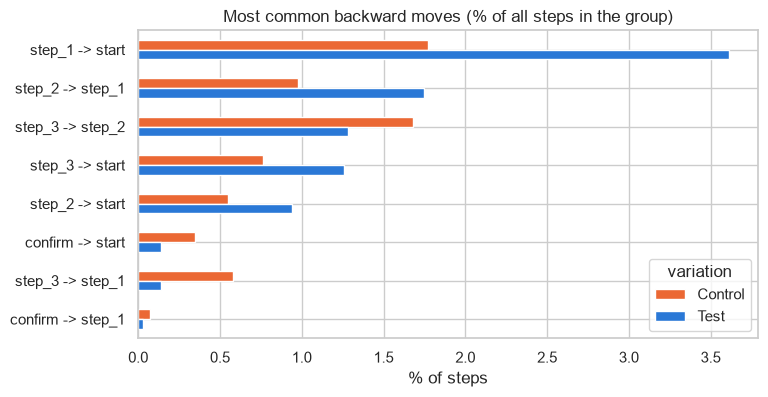

In [18]:
top_moves = moves_pct.head(8)
top_moves[["Control", "Test"]].plot(kind="barh", color=[colors["Control"], colors["Test"]])
plt.title("Most common backward moves (% of all steps in the group)")
plt.xlabel("% of steps")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.show()

**Reading:** the biggest difference is **`step_1 → start`**: Test clients go back from step 1 to the start page about **twice as often** as Control clients. `step_2 → step_1` is also higher in Test. In Control, the most common move is `step_3 → step_2`.

### 8.3 Error rate by step
For each step: how often did clients leave that step by going **backwards**?

In [19]:
steps_reached = df.groupby(["previous_step", "variation"]).size().unstack(fill_value=0)
back_from = backward_df.groupby(["previous_step", "variation"]).size().unstack(fill_value=0)

back_from_pct = (back_from / steps_reached * 100).round(2)
back_from_pct = back_from_pct.reindex(["start", "step_1", "step_2", "step_3", "confirm"]).dropna(how="all")
back_from_pct

variation,Control,Test
previous_step,,
step_1,9.54,17.94
step_2,8.89,16.11
step_3,20.87,19.78
confirm,32.17,7.19


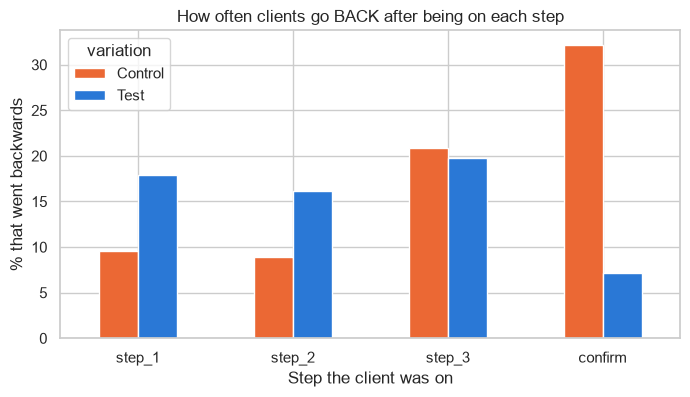

In [20]:
back_from_pct[["Control", "Test"]].plot(kind="bar", color=[colors["Control"], colors["Test"]])
plt.title("How often clients go BACK after being on each step")
plt.xlabel("Step the client was on")
plt.ylabel("% that went backwards")
plt.xticks(rotation=0)
plt.show()

**Reading:** after `step_1` and `step_2`, Test clients go back **about twice as often** as Control (around 18% vs 9–10% and 16% vs 9%). On `step_3` both groups are similar. After `confirm`, Control clients go back much more often than Test. So the **friction in the new design is concentrated in the first steps** (`step_1` and `step_2`).

### 8.4 Do errors affect completion?
For each visit: did it have a backward step (`had_error`) and did it reach `confirm` (`completed`)?

In [21]:
visit_summary = df.groupby(["variation", "visit_key"]).agg(
    had_error=("backward", "any"),
    completed=("process_step", lambda s: (s == "confirm").any())
).reset_index()

completion_by_error = (visit_summary.groupby(["variation", "had_error"])["completed"].mean() * 100).round(2).unstack()
completion_by_error.columns = ["No error", "With error"]
completion_by_error

,No error,With error
variation,,
Control,49.23,52.56
Test,64.53,42.29


In [22]:
overall_completion = (visit_summary.groupby("variation")["completed"].mean() * 100).round(2)
print("Completion rate per group (% of visits that reached 'confirm'):")
print(overall_completion)

Completion rate per group (% of visits that reached 'confirm'):
variation
Control    49.90
Test       58.57
Name: completed, dtype: float64


**Reading:**
- In the **Test** group, visits **without errors** complete much more often than visits **with errors** (about 64% vs 43%). So errors in the new design really **hurt completion**.
- In **Control**, visits with errors complete about as often as visits without (around 49–53%). Going back in the old design seems less harmful.
- Overall, Test still completes more visits than Control. If the new design's errors (especially at `step_1`) were reduced, its completion rate could be even higher.

### 8.5 Does the error rate change over time?
The experiment ran from March to June 2017. If one group's error rate changes a lot over the weeks, something other than the design may be influencing the result.

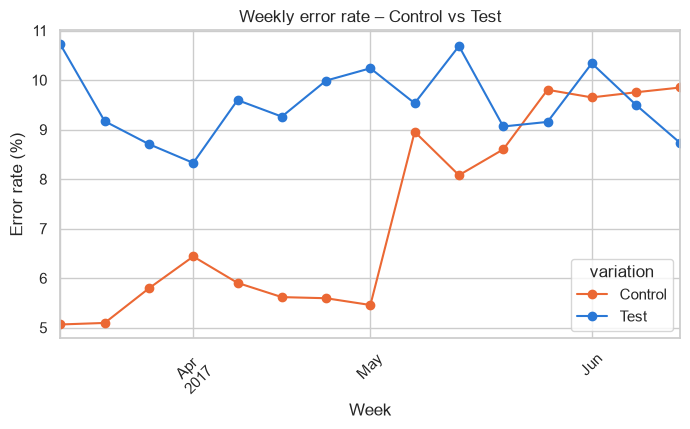

In [23]:
df["week"] = df["date_time"].dt.to_period("W").dt.start_time
weekly = df.groupby(["week", "variation"])["backward"].mean().unstack() * 100

weekly[["Control", "Test"]].plot(color=[colors["Control"], colors["Test"]], marker="o")
plt.title("Weekly error rate – Control vs Test")
plt.xlabel("Week")
plt.ylabel("Error rate (%)")
plt.xticks(rotation=45)
plt.show()

In [24]:
monthly = (df.assign(month=df["date_time"].dt.to_period("M"))
             .groupby(["month", "variation"])["backward"].mean().unstack() * 100).round(2)
monthly["Difference (pp)"] = (monthly["Test"] - monthly["Control"]).round(2)
monthly

variation,Control,Test,Difference (pp)
month,,,
2017-03,5.76,8.86,3.10
2017-04,6.03,9.02,2.99
2017-05,8.09,10.00,1.91
2017-06,9.76,9.41,-0.35


**Reading:**
- In **March, April and May** the Test error rate is clearly **higher** than Control (about +3 pp in March–April, +1.9 pp in May), so the result isn't caused by one unusual week.
- The gap **gets smaller over time** and disappears in **June**. Test errors stay roughly flat (~9–10%), while Control errors increase (from ~6% to ~10%).
- This may be a **learning effect** (clients get used to the new design), but the Control increase suggests that **later visitors behave differently** too. May–June also have far fewer visits than March–April, so treat this trend with care. Useful input for the **duration** question of the experiment evaluation.

## 9. Final interpretation: results summary
The values below are produced by the notebook (they update automatically if the data changes).

In [25]:
top_move = moves_pct["Test"].idxmax()
summary = pd.DataFrame({
    "Result": [
        "Official KPI – error rate (backward steps ÷ all steps)",
        "Step-level z-test",
        "Visit-level check – visits with ≥1 backward step",
        "Client-level check – clients with ≥1 backward step",
        "Most common backward move in Test",
    ],
    "Test": [f"{rate_test*100:.2f}%", "", f"{visit_table.loc['Test', 'visits_with_error_%']:.2f}%",
             f"{client_rate_test:.2f}%", top_move],
    "Control": [f"{rate_control*100:.2f}%", "", f"{visit_table.loc['Control', 'visits_with_error_%']:.2f}%",
                f"{client_rate_control:.2f}%", ""],
    "Difference / test": [f"{difference_pp:+.2f} pp", f"z = {z_stat:.2f}, p = {p_value:.1e} → reject H0",
                          f"p = {p_visit:.1e}", f"p = {p_client:.1e}",
                          f"{moves_pct.loc[top_move, 'Test']:.2f}% vs {moves_pct.loc[top_move, 'Control']:.2f}% of steps"],
})
summary

,Result,Test,Control,Difference / test
0,Official KPI – error rate (backward steps ÷ al...,9.16%,6.75%,+2.41 pp
1,Step-level z-test,,,"z = 24.69, p = 1.2e-134 → reject H0"
2,Visit-level check – visits with ≥1 backward step,26.78%,20.02%,p = 5.2e-97
3,Client-level check – clients with ≥1 backward ...,33.39%,25.82%,p = 7.3e-77
4,Most common backward move in Test,step_1 -> start,,3.61% vs 1.77% of steps


1. **Official KPI:** the backward-step rate was **9.16%** in Test and **6.75%** in Control, a difference of **+2.41 percentage points**.
2. **Step-level test:** p-value < 0.001. At α = 0.05, we **reject** the null hypothesis. The error rates are different.
3. **Visit-level check:** **26.78%** of Test visits and **20.02%** of Control visits had at least one backward step (p < 0.001).
4. **Client-level check:** **33.39%** of Test clients and **25.82%** of Control clients had at least one backward step (p < 0.001).
5. **Where to investigate:** the most common backward move in Test is **`step_1 → start`** (about twice as frequent as in Control).
6. **Business interpretation:** the new design has a **higher** backward-step rate. This signals friction, especially in the first steps, and must be read together with completion rate and time spent per step.

### Important interpretation notes
- Statistical significance doesn't automatically mean the effect is large or practically important.
- A backward step is a **proxy** for possible confusion, not direct proof that the client made a mistake.
- The visit- and client-level checks don't replace the official KPI. They confirm the same pattern when each visit or client counts only once.

## 10. Conclusions

### 1. Error rates
The Test group had an error rate of **9.16%**, compared with **6.75%** in Control: an increase of **2.41 percentage points** (about **+36%** relative).

### 2. Statistical significance
The two-proportion z-test shows a statistically significant difference (p < 0.001). We reject the null hypothesis that both groups have the same error rate.

### 3. Robustness checks
The difference stays significant when each visit or each client counts once: **26.8% vs 20.0%** of visits and **33.4% vs 25.8%** of clients had at least one backward step.

### 4. Where does the Test group struggle?
In the **first steps** of the process: `step_1 → start` (about 2× Control) and `step_2 → step_1`. After `step_1` and `step_2`, Test clients go back about twice as often as Control.

### 5. Business recommendation
The new design is associated with **more backward navigation**, concentrated at **`step_1`**. This matches the time-spent analysis, where `step_1` is the only step on which the new design is slower. In the Test group, errors clearly reduce completion. **Recommendation:** keep the new design (higher completion, faster overall, see the other KPIs), but **review and simplify `step_1`** before the full rollout.

### 6. Limitations
- The step-level test treats steps as independent, but steps in the same visit/client are related. The visit- and client-level checks reduce this concern.
- The error gap shrinks over the months and disappears in June (possible learning effect), but May–June have much less data.
- We don't know *why* clients went back (no click, field-error or device data).

## 11. Group hand-off checklist
Items for the **whole project team**, to check before the presentation:

- [ ] Completion-rate test between Test and Control (hypotheses, p-value, confidence interval)
- [ ] 5% cost-effectiveness threshold test. Document whether "5%" means percentage points or relative
- [ ] One additional hypothesis test
- [ ] Experiment evaluation: design effectiveness (randomisation, group balance, bias), duration, additional data needs
- [ ] **Combine completion rate, time spent and error rate** into one business recommendation. All three point to **`step_1`** as the weak point of the new design
- [ ] Use the **same colours** for Control and Test in every chart (Control = orange, Test = blue)